,Recall,Precision,F1,ROC-AUC
Baseline,0.000000,0.000000,0.000000,0.500000
Logistic Regression,0.748906,0.348665,0.475808,0.801199
Decision Tree,0.766054,0.334989,0.466019,0.796117
Random Forest,0.720965,0.362022,0.482008,0.805256


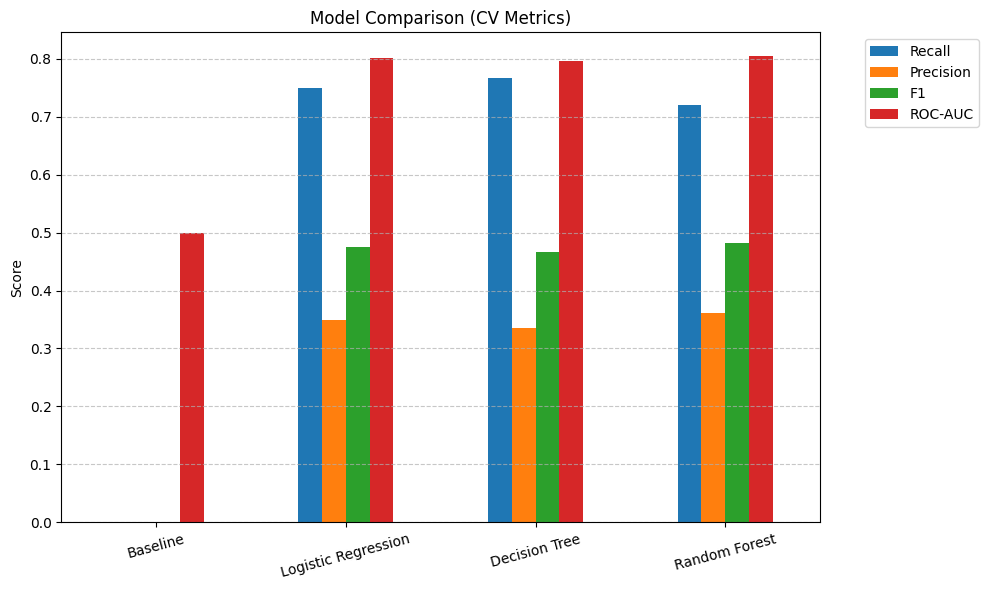

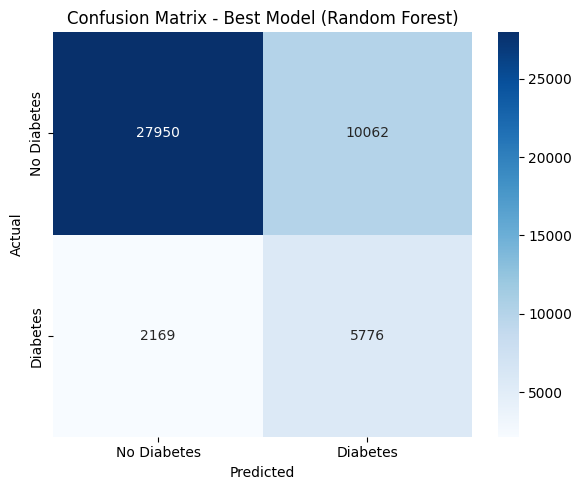


=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

           0       0.93      0.74      0.82     38012
           1       0.36      0.73      0.49      7945

    accuracy                           0.73     45957
   macro avg       0.65      0.73      0.65     45957
weighted avg       0.83      0.73      0.76     45957



In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
np.random.seed(SEED)

DATA_PATH = "/content/diabetes_012_health_indicators_BRFSS2015.csv"
df = pd.read_csv(DATA_PATH)

target_col = "Diabetes_binary" if "Diabetes_binary" in df.columns else "Diabetes_012"
df_clean = df.drop_duplicates().copy()

if target_col == "Diabetes_012":
    y = (df_clean[target_col] > 0).astype(int)
else:
    y = df_clean[target_col].astype(int)

X = df_clean.drop(columns=[target_col])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

continuous_cols = [c for c in ["BMI", "MentHlth", "PhysHlth"] if c in X.columns]
other_cols = [c for c in X.columns if c not in continuous_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), continuous_cols),
        ("passthrough", "passthrough", other_cols),
    ]
)

models = {
    "Baseline": DummyClassifier(strategy="most_frequent", random_state=SEED),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=SEED),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_results = {}
for name, clf in models.items():
    pipe = Pipeline(steps=[("prep", preprocessor), ("model", clf)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results[name] = {
        "Recall": scores["test_recall"].mean(),
        "Precision": scores["test_precision"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    }

df_results = pd.DataFrame(cv_results).T
display(df_results)

plt.figure(figsize=(10, 6))
df_results.plot(kind="bar", ax=plt.gca())
plt.title("Model Comparison (CV Metrics)")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

best_pipe = Pipeline(
    steps=[
        ("prep", preprocessor),
        ("model", RandomForestClassifier(n_estimators=150, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=SEED)),
    ]
)
best_pipe.fit(X_train, y_train)

y_pred = best_pipe.predict(X_test)
y_prob = best_pipe.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No Diabetes", "Diabetes"], yticklabels=["No Diabetes", "Diabetes"])
plt.title("Confusion Matrix - Best Model (Random Forest)")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()

print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred))

In [6]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df_results)

https://docs.google.com/spreadsheets/d/1toAl2Wemrfe19MkQCyvzzVeCe2EQAv8MHLXdQ9GeVpQ/edit#gid=0
